# Credit Train — Exploratory Data Analysis

**Dataset:** `Datasets/credit_train.csv`
**Unit of analysis:** Loan application (`Loan ID`)
**Target:** Loan outcome — *Fully Paid* vs *Charged Off* (default)

---

### Purpose

This notebook profiles the raw training data before modelling. It establishes the **data quality contract** used in all downstream stages: cleaning rules, missingness patterns, target definition, and the strongest bivariate relationships with default.

### Scope

1. Shape, schema, and basic integrity checks
2. Missing values and sentinel codes
3. Univariate distributions for numeric and categorical fields
4. Target balance and default rate
5. Bivariate analysis versus default
6. Summary of cleaning rules for feature engineering


## 0. Setup

Import libraries, set display options, and resolve paths to the project datasets.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

DATA = Path("../../Datasets/credit_train.csv")
assert DATA.exists(), f"Missing {DATA.resolve()}"
print("Ready.")


Ready.


## 1. Data contract & quality profile

**Source:** `credit_train.csv`
**Grain:** one row per Loan ID (with known duplicates)
**Target:** `Loan Status` ∈ {Fully Paid, Charged Off}
**Sensitive fields:** none explicit (IDs are synthetic UUIDs)


In [2]:
df = pd.read_csv(DATA)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
df.head(3)


Shape: 100,000 rows × 19 columns
Memory: 56.3 MB


,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412,Short Term,709.00,1167493.00,8 years,Home Mortgage,Home Improvements,5214.74,17.20,NaN,6,1,228190,416746.00,1.00,0.00
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328,Short Term,NaN,NaN,10+ years,Home Mortgage,Debt Consolidation,33295.98,21.10,8.00,35,0,229976,850784.00,0.00,0.00
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999,Short Term,741.00,2231892.00,8 years,Own Home,Debt Consolidation,29200.53,14.90,29.00,18,1,297996,750090.00,0.00,0.00


In [3]:
# Schema overview
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "nulls": df.isna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "nunique": df.nunique(dropna=True),
})
schema


,dtype,non_null,nulls,null_pct,nunique
Loan ID,str,100000,0,0.00,81999
Customer ID,str,100000,0,0.00,81999
Loan Status,str,100000,0,0.00,2
Current Loan Amount,int64,100000,0,0.00,22004
Term,str,100000,0,0.00,2
Credit Score,float64,80846,19154,19.15,324
Annual Income,float64,80846,19154,19.15,36174
Years in current job,str,95778,4222,4.22,11
Home Ownership,str,100000,0,0.00,4
Purpose,str,100000,0,0.00,16


In [4]:
# Duplicate analysis
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate Loan IDs:   {df['Loan ID'].duplicated().sum():,}")
print(f"Duplicate Customer IDs: {df['Customer ID'].duplicated().sum():,}")

# Keep first occurrence for analysis (preserve original for audit)
df_clean = df.drop_duplicates(subset=["Loan ID"]).copy()
print(f"\nAfter Loan-ID dedup: {df_clean.shape[0]:,} rows")


Exact duplicate rows: 10,215
Duplicate Loan IDs:   18,001
Duplicate Customer IDs: 18,001

After Loan-ID dedup: 81,999 rows


### Data quality notes (observed)

| Issue | Detail | Handling in this notebook |
|-------|--------|---------------------------|
| Credit Score outliers | Values > 850 are typically true score × 10 | Divide by 10 when > 850 |
| Loan amount sentinel | `99999999` ≈ unknown | Treat as missing |
| High missingness | Credit Score / Income (~19%), Months since delinquent (~53%) | Profile as-is; flag for imputation later |
| Category noise | `HaveMortgage`, mixed-case Purpose | Normalise for analysis |
| Duplicates | ~18k repeated Loan IDs | Deduplicate on Loan ID |


In [5]:
# Apply cleaning for analysis
d = df_clean.copy()

# Credit score fix
mask_cs = d["Credit Score"] > 850
print(f"Credit scores fixed (>850): {mask_cs.sum():,}")
d.loc[mask_cs, "Credit Score"] = d.loc[mask_cs, "Credit Score"] / 10

# Loan amount sentinel
n_sent = (d["Current Loan Amount"] == 99999999).sum()
print(f"Loan amount sentinels (99999999): {n_sent:,}")
d["Current Loan Amount"] = d["Current Loan Amount"].replace(99999999, np.nan)

# Home ownership
d["Home Ownership"] = d["Home Ownership"].replace({"HaveMortgage": "Home Mortgage"})

# Purpose normalisation
d["Purpose"] = d["Purpose"].str.lower().str.replace(" ", "_")

# Job tenure ordinal (for later correlation)
job_map = {
    "< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
    "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
    "10+ years": 10, "n/a": np.nan,
}
d["Job_Years_Num"] = d["Years in current job"].map(job_map)

# Binary target
d["Default"] = (d["Loan Status"] == "Charged Off").astype(int)
print(f"\nAnalysis frame: {d.shape[0]:,} rows")


Credit scores fixed (>850): 4,551
Loan amount sentinels (99999999): 9,688

Analysis frame: 81,999 rows


## 2. Target distribution

Inspect the class balance for *Fully Paid* versus *Charged Off* after basic cleaning. The default rate drives later choices on class weights and decision thresholds.


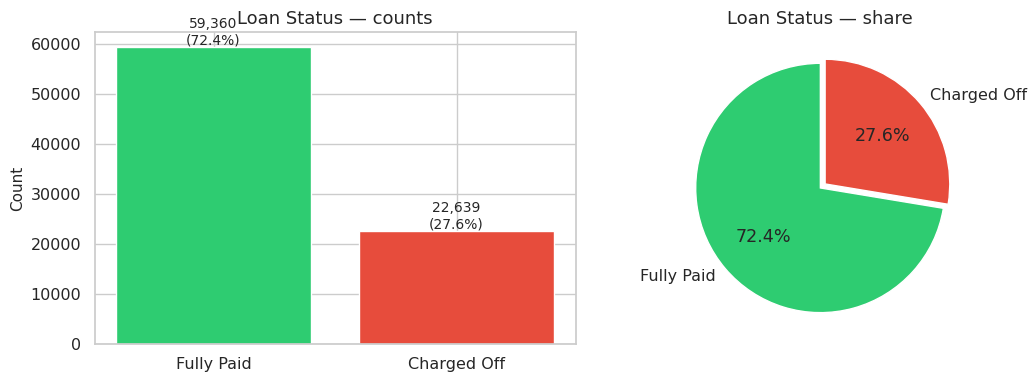

Default rate: 27.61%
Class imbalance ratio (Paid:Default): 2.62:1


In [6]:
target_counts = d["Loan Status"].value_counts()
target_pct = d["Loan Status"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#2ecc71", "#e74c3c"]
axes[0].bar(target_counts.index, target_counts.values, color=colors)
axes[0].set_title("Loan Status — counts")
axes[0].set_ylabel("Count")
for i, (v, p) in enumerate(zip(target_counts.values, target_pct.values)):
    axes[0].text(i, v + 500, f"{v:,}\n({p:.1f}%)", ha="center", fontsize=10)

axes[1].pie(target_counts, labels=target_counts.index, autopct="%1.1f%%",
            colors=colors, startangle=90, explode=(0, 0.05))
axes[1].set_title("Loan Status — share")
plt.tight_layout()
plt.show()

print(f"Default rate: {d['Default'].mean()*100:.2f}%")
print(f"Class imbalance ratio (Paid:Default): {(1-d['Default'].mean())/d['Default'].mean():.2f}:1")


## 3. Univariate distributions — numeric features

Summarise central tendency, spread, and tail behaviour for continuous credit and loan attributes.


In [7]:
num_cols = [
    "Current Loan Amount", "Credit Score", "Annual Income", "Monthly Debt",
    "Years of Credit History", "Months since last delinquent",
    "Number of Open Accounts", "Number of Credit Problems",
    "Current Credit Balance", "Maximum Open Credit",
    "Bankruptcies", "Tax Liens", "Job_Years_Num",
]
num_cols = [c for c in num_cols if c in d.columns]

summary = d[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
summary["missing_pct"] = (d[num_cols].isna().mean() * 100).round(2)
summary


,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_pct
Current Loan Amount,72311.00,308016.69,182588.65,10802.00,35400.20,171952.00,265430.00,429220.00,778624.00,789250.00,11.81
Credit Score,64968.00,720.23,27.79,585.00,623.67,708.00,728.00,741.00,751.00,751.00,20.77
Annual Income,64968.00,1376776.24,1121541.74,76627.00,346104.00,847305.00,1169592.50,1649437.50,4551618.72,165557393.00,20.77
Monthly Debt,81999.00,18330.63,12127.70,0.00,1235.75,10117.60,16075.33,23811.37,58543.92,435843.28,0.00
Years of Credit History,81999.00,18.30,7.04,3.60,6.50,13.50,17.00,21.80,40.40,70.50,0.00
Months since last delinquent,37378.00,35.06,22.02,0.00,1.00,16.00,32.00,51.00,81.00,176.00,54.42
Number of Open Accounts,81999.00,11.11,4.98,0.00,3.00,8.00,10.00,14.00,27.00,76.00,0.00
Number of Credit Problems,81999.00,0.16,0.47,0.00,0.00,0.00,0.00,0.00,2.00,15.00,0.00
Current Credit Balance,81999.00,293620.31,372614.51,0.00,2660.00,113316.00,209931.00,366994.50,1539760.76,32878968.00,0.00
Maximum Open Credit,81997.00,793535.81,9208747.41,0.00,26818.00,280456.00,477774.00,798490.00,3728199.20,1539737892.00,0.00


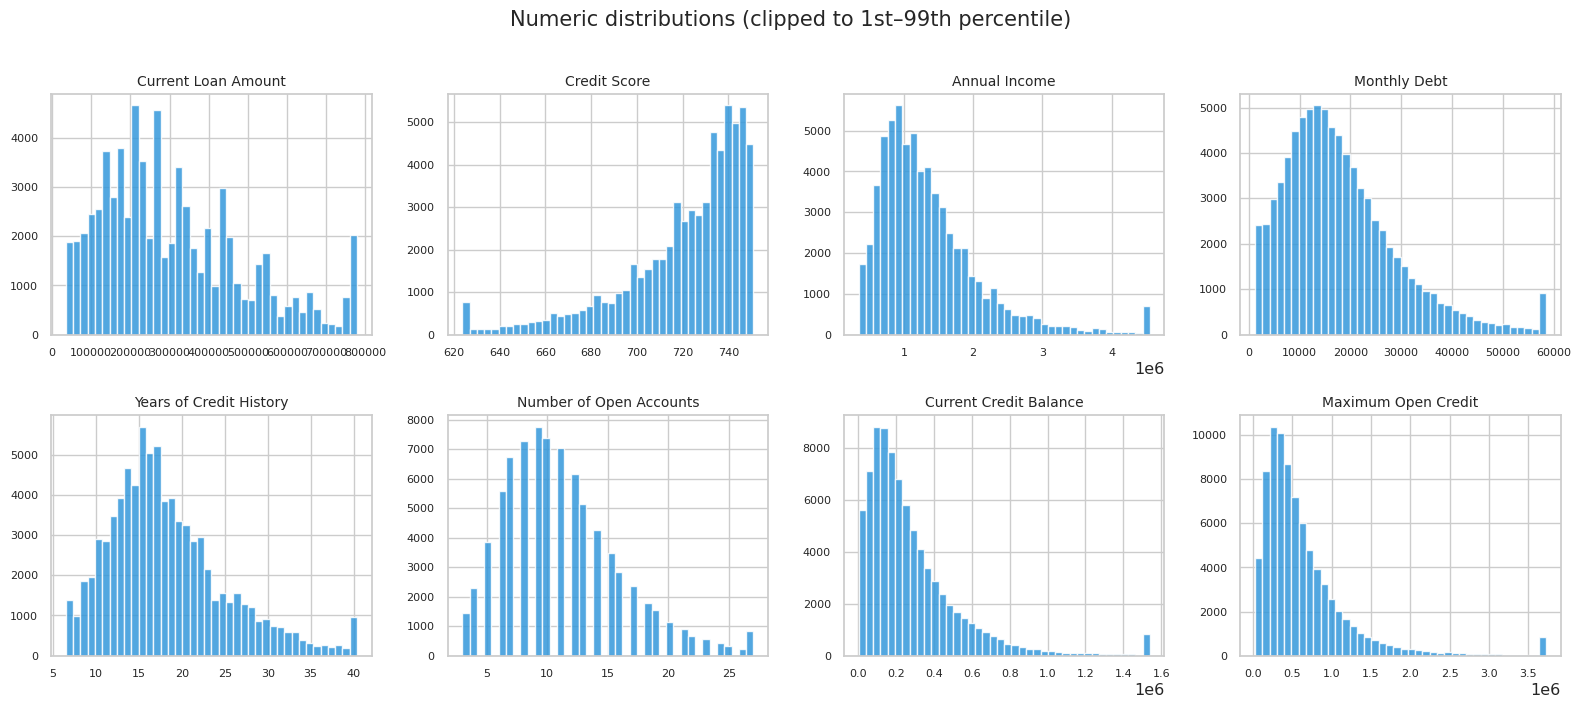

In [8]:
# Distribution grid
plot_cols = [
    "Current Loan Amount", "Credit Score", "Annual Income", "Monthly Debt",
    "Years of Credit History", "Number of Open Accounts",
    "Current Credit Balance", "Maximum Open Credit",
]
plot_cols = [c for c in plot_cols if c in d.columns]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
for i, col in enumerate(plot_cols):
    s = d[col].dropna()
    # Cap display at 99th pct to reduce outlier distortion
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    axes[i].hist(s.clip(lo, hi), bins=40, color="#3498db", edgecolor="white", alpha=0.85)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(labelsize=8)
for j in range(len(plot_cols), len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Numeric distributions (clipped to 1st–99th percentile)", y=1.01)
plt.tight_layout()
plt.show()


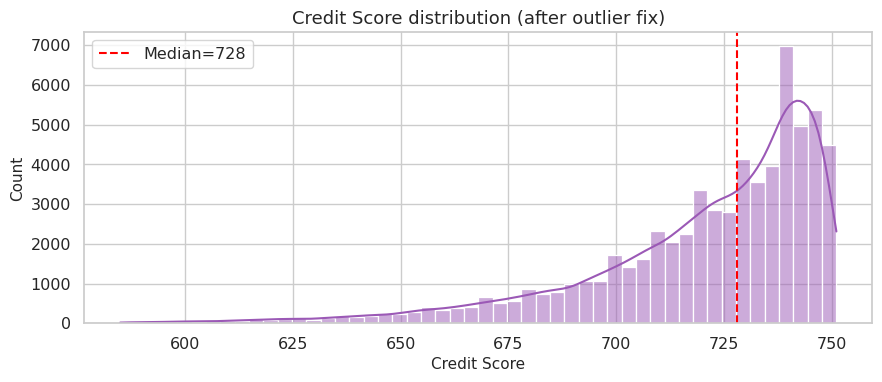

count   64968.00
mean      720.23
std        27.79
min       585.00
25%       708.00
50%       728.00
75%       741.00
max       751.00
Name: Credit Score, dtype: float64


In [9]:
# Credit Score detail (post-fix)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(d["Credit Score"].dropna(), bins=50, kde=True, ax=ax, color="#9b59b6")
ax.axvline(d["Credit Score"].median(), color="red", ls="--", label=f"Median={d['Credit Score'].median():.0f}")
ax.set_title("Credit Score distribution (after outlier fix)")
ax.legend()
plt.tight_layout()
plt.show()
print(d["Credit Score"].describe())


## 4. Univariate distributions — categorical features

Frequency profiles for term, home ownership, purpose, and job tenure — high-cardinality levels will be grouped in feature engineering.


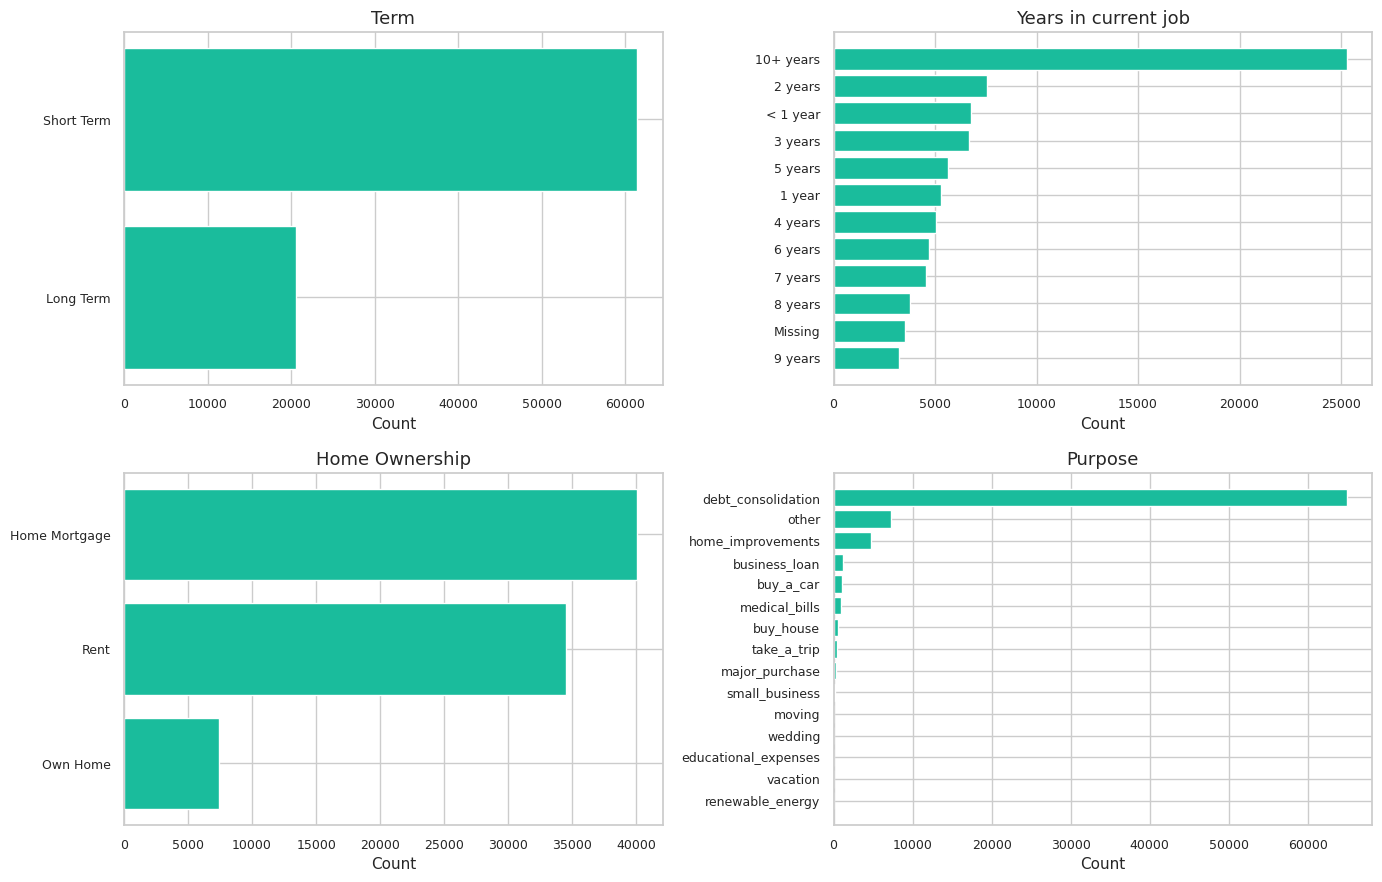


--- Term ---
Term
Short Term   74.90
Long Term    25.10

--- Years in current job ---
Years in current job
10+ years   30.80
2 years      9.20
< 1 year     8.20
3 years      8.10
5 years      6.90
1 year       6.50
4 years      6.10
6 years      5.70
7 years      5.60
8 years      4.60
Missing      4.30
9 years      3.90

--- Home Ownership ---
Home Ownership
Home Mortgage   48.80
Rent            42.10
Own Home         9.10

--- Purpose ---
Purpose
debt_consolidation   79.20
other                 8.80
home_improvements     5.80
business_loan         1.50
buy_a_car             1.30
medical_bills         1.10
buy_house             0.60
take_a_trip           0.50
major_purchase        0.40
small_business        0.30
moving                0.10
wedding               0.10


In [10]:
cat_cols = ["Term", "Years in current job", "Home Ownership", "Purpose"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()
for i, col in enumerate(cat_cols):
    vc = d[col].fillna("Missing").value_counts()
    axes[i].barh(vc.index.astype(str)[::-1], vc.values[::-1], color="#1abc9c")
    axes[i].set_title(col)
    axes[i].set_xlabel("Count")
    axes[i].tick_params(labelsize=9)
plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(d[col].fillna("Missing").value_counts(normalize=True).mul(100).round(1).head(12).to_string())


## 5. Bivariate analysis — features vs Loan Status

Default rate by segment is the primary risk lens.


Default rate by Term:
            default_rate      n
Term                           
Long Term          40.59  20612
Short Term         23.25  61387


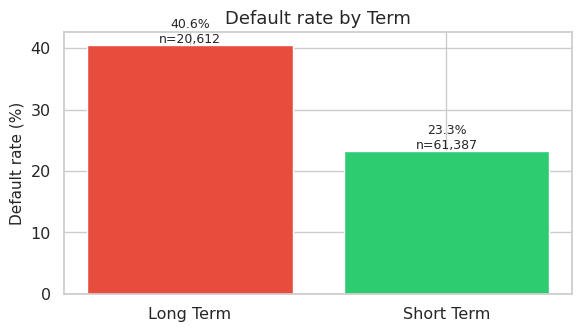

In [11]:
def default_rate_by(col, top_n=None, order=None):
    tmp = d.copy()
    tmp[col] = tmp[col].fillna("Missing")
    g = tmp.groupby(col)["Default"].agg(["mean", "count"])
    g.columns = ["default_rate", "n"]
    g["default_rate"] = g["default_rate"] * 100
    if top_n:
        g = g.nlargest(top_n, "n")
    if order:
        g = g.reindex([x for x in order if x in g.index])
    return g.sort_values("default_rate", ascending=False)

# Term
term_dr = default_rate_by("Term")
print("Default rate by Term:")
print(term_dr.to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(term_dr.index, term_dr["default_rate"], color=["#e74c3c", "#2ecc71"])
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by Term")
for i, (r, n) in enumerate(zip(term_dr["default_rate"], term_dr["n"])):
    ax.text(i, r + 0.3, f"{r:.1f}%\nn={n:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


                default_rate      n
Home Ownership                     
Rent                   30.71  34499
Own Home               28.18   7458
Home Mortgage          24.83  40042


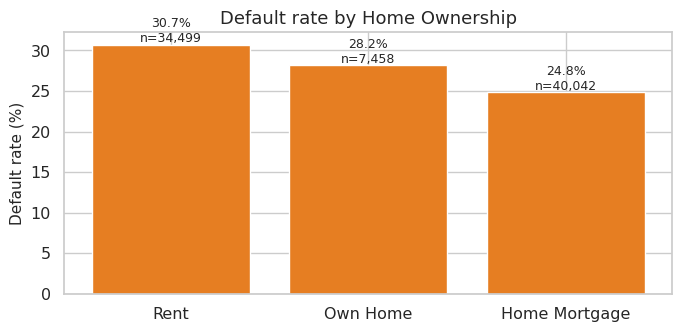

In [12]:
# Home Ownership
ho_dr = default_rate_by("Home Ownership")
print(ho_dr.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(ho_dr.index, ho_dr["default_rate"], color="#e67e22")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by Home Ownership")
for i, (r, n) in enumerate(zip(ho_dr["default_rate"], ho_dr["n"])):
    ax.text(i, r + 0.3, f"{r:.1f}%\nn={n:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


                      default_rate      n
Purpose                                  
small_business               51.74    230
renewable_energy             50.00      8
business_loan                38.89   1229
moving                       37.07    116
vacation                     36.25     80
medical_bills                31.59    880
other                        27.99   7238
debt_consolidation           27.61  64907
major_purchase               27.06    303
buy_house                    26.97    519
take_a_trip                  26.44    435
wedding                      24.73     93
home_improvements            24.25   4795
educational_expenses         21.18     85
buy_a_car                    18.78   1081


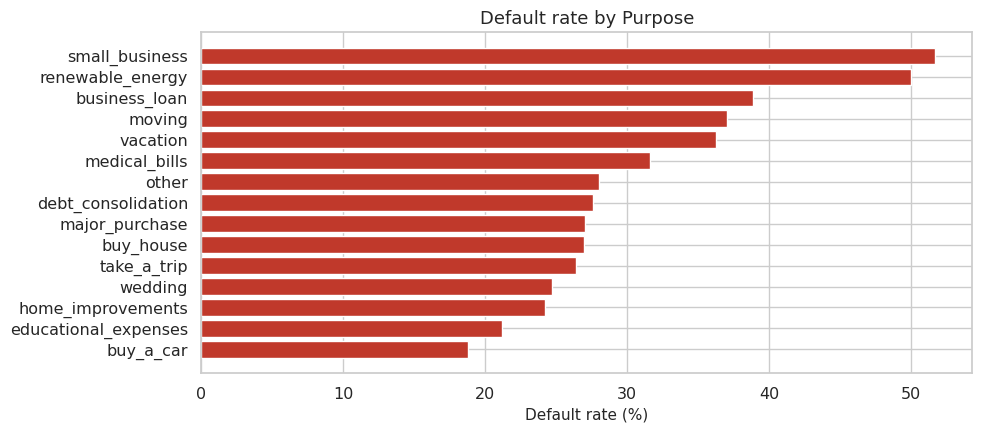

In [13]:
# Purpose
pur_dr = default_rate_by("Purpose")
print(pur_dr.to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(pur_dr.index[::-1], pur_dr["default_rate"].values[::-1], color="#c0392b")
ax.set_xlabel("Default rate (%)")
ax.set_title("Default rate by Purpose")
plt.tight_layout()
plt.show()


                      default_rate      n
Years in current job                     
Missing                      36.26   3508
9 years                      29.25   3220
< 1 year                     28.25   6755
7 years                      28.23   4566
1 year                       28.08   5317
6 years                      28.07   4702
8 years                      27.80   3781
4 years                      27.36   5029
5 years                      27.26   5619
10+ years                    26.61  25271
2 years                      26.48   7560
3 years                      25.93   6671


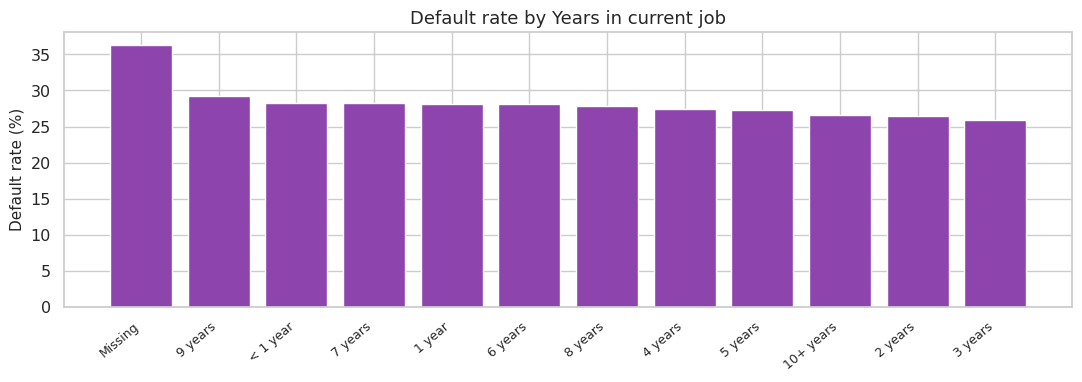

In [14]:
# Years in current job
job_order = ["< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years",
             "6 years", "7 years", "8 years", "9 years", "10+ years", "Missing"]
job_dr = default_rate_by("Years in current job", order=job_order)
print(job_dr.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(job_dr)), job_dr["default_rate"], color="#8e44ad")
ax.set_xticks(range(len(job_dr)))
ax.set_xticklabels(job_dr.index, rotation=40, ha="right", fontsize=9)
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by Years in current job")
plt.tight_layout()
plt.show()


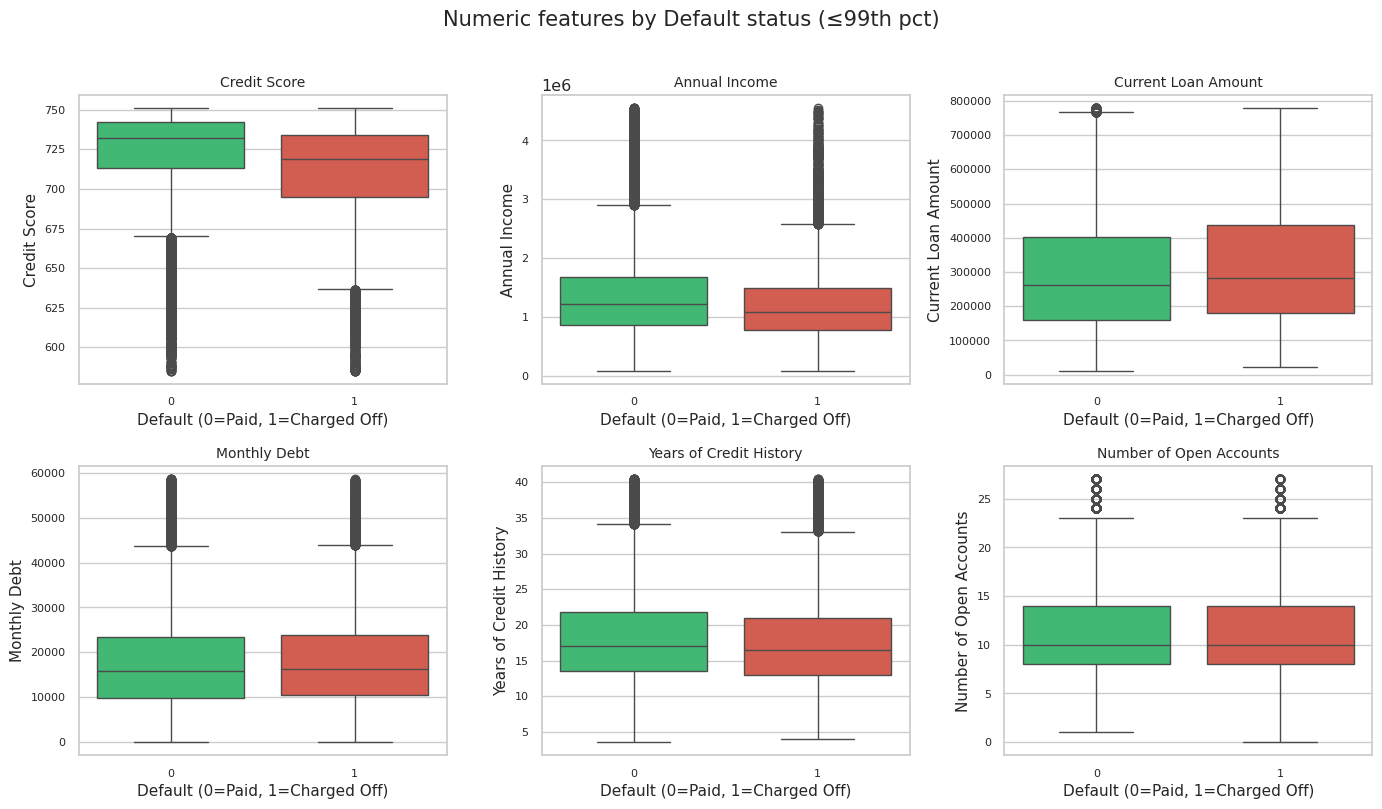

In [15]:
# Numeric features: boxplots by Default
box_cols = ["Credit Score", "Annual Income", "Current Loan Amount",
            "Monthly Debt", "Years of Credit History", "Number of Open Accounts"]
box_cols = [c for c in box_cols if c in d.columns]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, col in enumerate(box_cols):
    # Clip for readability
    s = d[[col, "Default"]].dropna()
    hi = s[col].quantile(0.99)
    s = s[s[col] <= hi]
    sns.boxplot(data=s, x="Default", y=col, ax=axes[i], palette=["#2ecc71", "#e74c3c"])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("Default (0=Paid, 1=Charged Off)")
    axes[i].tick_params(labelsize=8)
plt.suptitle("Numeric features by Default status (≤99th pct)", y=1.01)
plt.tight_layout()
plt.show()


In [16]:
# Mean comparison table
cmp = d.groupby("Loan Status")[num_cols].mean().T
cmp.columns = ["Fully Paid (mean)", "Charged Off (mean)"]
cmp["pct_diff"] = ((cmp["Charged Off (mean)"] - cmp["Fully Paid (mean)"]) /
                   cmp["Fully Paid (mean)"] * 100)
cmp = cmp.sort_values("pct_diff", key=abs, ascending=False)
cmp


,Fully Paid (mean),Charged Off (mean),pct_diff
Maximum Open Credit,630533.79,855696.81,35.71
Tax Liens,0.03,0.03,-24.75
Annual Income,1267789.54,1416050.53,11.69
Current Loan Amount,324975.23,300287.50,-7.60
Number of Credit Problems,0.17,0.16,-7.27
Years of Credit History,17.89,18.45,3.13
Months since last delinquent,34.34,35.34,2.93
Current Credit Balance,287918.03,295795.08,2.74
Monthly Debt,18650.57,18208.62,-2.37
Credit Score,710.39,723.77,1.88


## 6. Derived risk ratios

| Ratio | Formula | Interpretation |
|-------|---------|----------------|
| DTI | (Monthly Debt × 12) / Annual Income | Debt burden |
| Credit Util | Current Balance / Max Open Credit | Revolving utilisation |
| LTI | Current Loan Amount / Annual Income | Loan size relative to income |


In [17]:
d["DTI"] = np.where(d["Annual Income"] > 0,
                    (d["Monthly Debt"] * 12) / d["Annual Income"], np.nan)
d["Credit_Util"] = np.where(d["Maximum Open Credit"] > 0,
                            d["Current Credit Balance"] / d["Maximum Open Credit"], np.nan)
d["Credit_Util"] = d["Credit_Util"].clip(upper=2.0)
d["LTI"] = np.where(d["Annual Income"] > 0,
                    d["Current Loan Amount"] / d["Annual Income"], np.nan)

ratio_cols = ["DTI", "Credit_Util", "LTI"]
print(d[ratio_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).to_string())


           DTI  Credit_Util      LTI
count 64968.00     81428.00 55280.00
mean      0.17         0.48     0.25
std       0.08         0.21     0.13
min       0.00         0.00     0.00
25%       0.11         0.33     0.15
50%       0.17         0.49     0.24
75%       0.23         0.64     0.35
95%       0.31         0.80     0.49
max       0.40         2.00     1.31


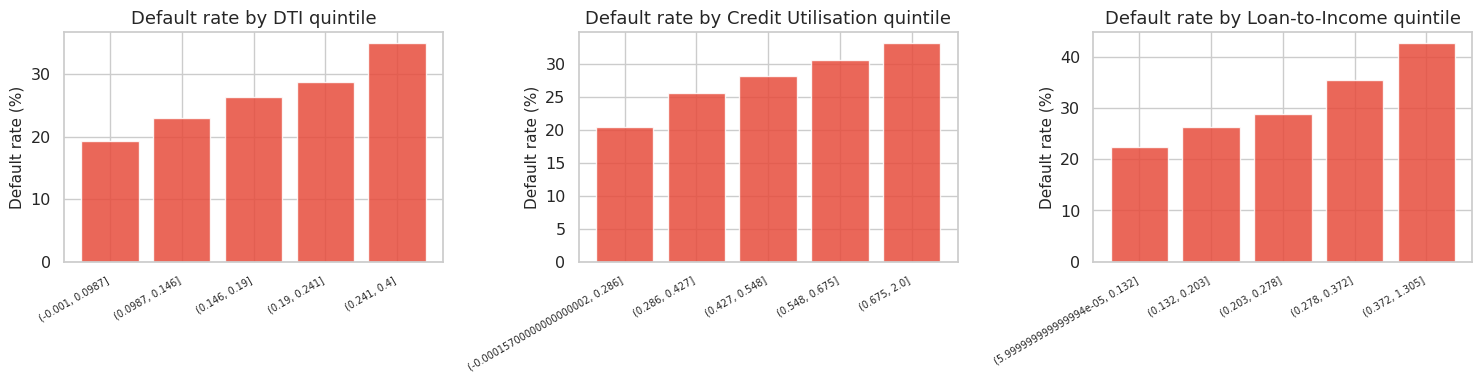

In [18]:
# Default rate by DTI / Util / LTI quintiles
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ratio_cols, ["DTI", "Credit Utilisation", "Loan-to-Income"]):
    tmp = d[[col, "Default"]].dropna()
    tmp["bin"] = pd.qcut(tmp[col], 5, duplicates="drop")
    rates = tmp.groupby("bin", observed=True)["Default"].mean() * 100
    ax.bar(range(len(rates)), rates.values, color="#e74c3c", alpha=0.85)
    ax.set_xticks(range(len(rates)))
    ax.set_xticklabels([str(x) for x in rates.index], rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("Default rate (%)")
    ax.set_title(f"Default rate by {title} quintile")
plt.tight_layout()
plt.show()


## 7. Correlation structure

Pairwise associations among numeric fields highlight multicollinearity that feature selection must resolve.


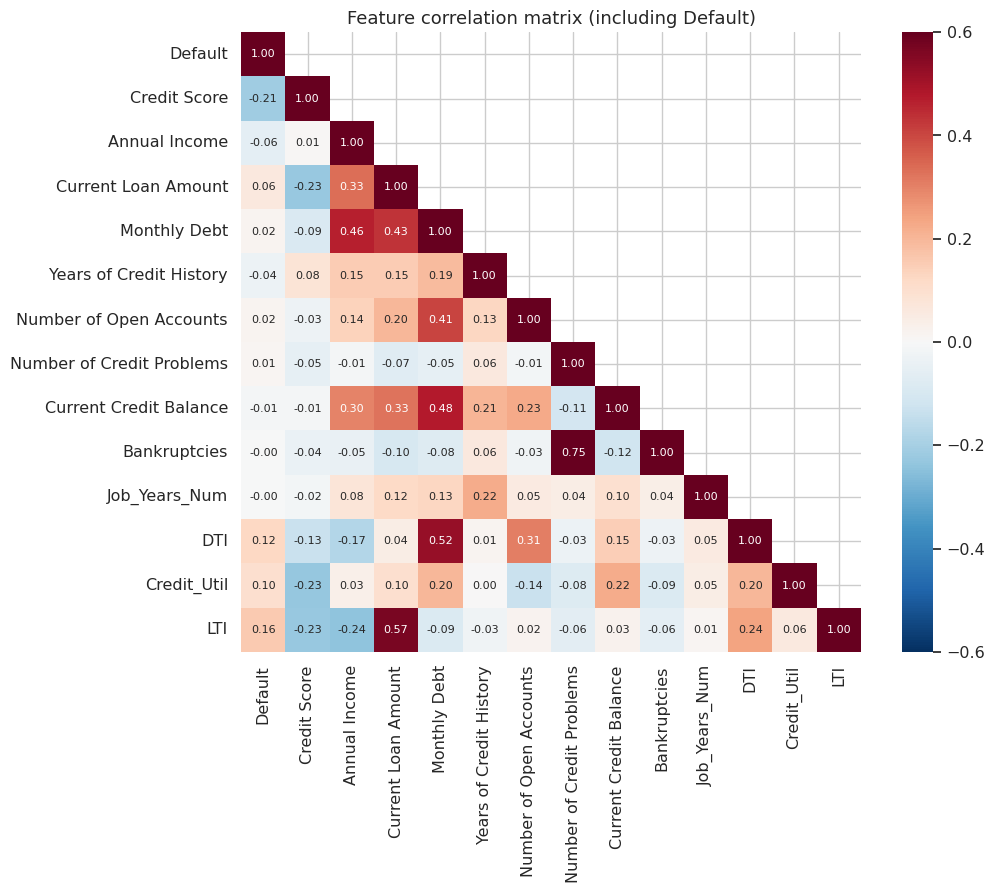

In [19]:
corr_cols = [
    "Default", "Credit Score", "Annual Income", "Current Loan Amount",
    "Monthly Debt", "Years of Credit History", "Number of Open Accounts",
    "Number of Credit Problems", "Current Credit Balance", "Bankruptcies",
    "Job_Years_Num", "DTI", "Credit_Util", "LTI",
]
corr_cols = [c for c in corr_cols if c in d.columns]
corr = d[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-0.6, vmax=0.6, ax=ax, square=True,
            annot_kws={"size": 8})
ax.set_title("Feature correlation matrix (including Default)")
plt.tight_layout()
plt.show()


Correlation with Default (absolute rank):
Credit Score                -0.21
LTI                          0.16
DTI                          0.12
Credit_Util                  0.10
Current Loan Amount          0.06
Annual Income               -0.06
Years of Credit History     -0.04
Monthly Debt                 0.02
Number of Open Accounts      0.02
Number of Credit Problems    0.01
Current Credit Balance      -0.01
Job_Years_Num               -0.00
Bankruptcies                -0.00


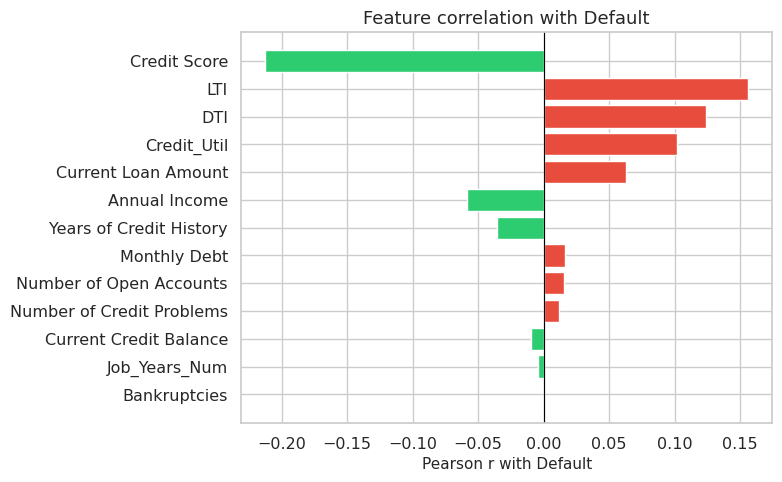

In [20]:
# Ranked correlations with Default
default_corr = corr["Default"].drop("Default").sort_values(key=abs, ascending=False)
print("Correlation with Default (absolute rank):")
print(default_corr.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#e74c3c" if v > 0 else "#2ecc71" for v in default_corr.values]
ax.barh(default_corr.index[::-1], default_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson r with Default")
ax.set_title("Feature correlation with Default")
plt.tight_layout()
plt.show()


## 8. Credit problems, bankruptcies & tax liens

Public-record style fields are sparse but economically meaningful; treat presence as a risk flag as well as the raw counts.


In [21]:
for col in ["Number of Credit Problems", "Bankruptcies", "Tax Liens"]:
    if col not in d.columns:
        continue
    g = d.groupby(col)["Default"].agg(["mean", "count"])
    g["default_rate"] = g["mean"] * 100
    print(f"\n=== {col} ===")
    print(g[["default_rate", "count"]].head(8).to_string())



=== Number of Credit Problems ===
                           default_rate  count
Number of Credit Problems                     
0                                 27.44  70990
1                                 28.35   9539
2                                 30.47   1014
3                                 29.35    293
4                                 36.84     95
5                                 42.50     40
6                                 23.08     13
7                                 33.33      6

=== Bankruptcies ===
              default_rate  count
Bankruptcies                     
0.00                 27.61  73101
1.00                 27.57   8296
2.00                 27.96    329
3.00                 25.00     72
4.00                 36.84     19
5.00                 40.00      5
6.00                  0.00      1
7.00                  0.00      1

=== Tax Liens ===
           default_rate  count
Tax Liens                     
0.00              27.52  80491
1.00              31.

In [22]:
# Has-any flags
d["Has_Credit_Problems"] = (d["Number of Credit Problems"].fillna(0) > 0).astype(int)
d["Has_Bankruptcy"] = (d["Bankruptcies"].fillna(0) > 0).astype(int)
d["Has_Tax_Lien"] = (d["Tax Liens"].fillna(0) > 0).astype(int)
d["Has_Delinquency_Hist"] = d["Months since last delinquent"].notna().astype(int)

flag_summary = []
for col in ["Has_Credit_Problems", "Has_Bankruptcy", "Has_Tax_Lien", "Has_Delinquency_Hist"]:
    rates = d.groupby(col)["Default"].mean() * 100
    flag_summary.append({
        "Flag": col,
        "Default_rate_when_0": rates.get(0, np.nan),
        "Default_rate_when_1": rates.get(1, np.nan),
        "Lift": rates.get(1, np.nan) / rates.get(0, np.nan) if rates.get(0, 0) else np.nan,
        "Prevalence_%": d[col].mean() * 100,
    })
pd.DataFrame(flag_summary).round(2)


,Flag,Default_rate_when_0,Default_rate_when_1,Lift,Prevalence_%
0,Has_Credit_Problems,27.44,28.69,1.05,13.43
1,Has_Bankruptcy,27.61,27.58,1.00,10.64
2,Has_Tax_Lien,27.52,32.60,1.18,1.83
3,Has_Delinquency_Hist,27.41,27.85,1.02,45.58


## 9. Missingness as a signal

In this dataset, missing income, score, or loan amount often correlates with outcome. Missingness indicators should be retained as features rather than only imputed away.


In [23]:
miss_cols = ["Credit Score", "Annual Income", "Months since last delinquent",
             "Years in current job", "Bankruptcies"]
rows = []
for col in miss_cols:
    if col not in d.columns:
        continue
    is_miss = d[col].isna()
    rows.append({
        "Feature": col,
        "Missing_%": is_miss.mean() * 100,
        "Default_rate_when_missing": d.loc[is_miss, "Default"].mean() * 100,
        "Default_rate_when_present": d.loc[~is_miss, "Default"].mean() * 100,
    })
miss_df = pd.DataFrame(rows)
miss_df["Lift_missing"] = miss_df["Default_rate_when_missing"] / miss_df["Default_rate_when_present"]
miss_df.round(2)


,Feature,Missing_%,Default_rate_when_missing,Default_rate_when_present,Lift_missing
0,Credit Score,20.77,31.88,26.49,1.20
1,Annual Income,20.77,31.88,26.49,1.20
2,Months since last delinquent,54.42,27.41,27.85,0.98
3,Years in current job,4.28,36.26,27.22,1.33
4,Bankruptcies,0.21,28.57,27.61,1.03


## 10. Key findings & recommendations

### Decision-relevant findings

1. **Base default rate ≈ 25%** after deduplication — moderate class imbalance (~3:1). Models should use class weights or threshold tuning; accuracy alone is misleading.

2. **Term is a strong segmenter.** Long-term loans show a materially higher default rate than short-term. This should be a first-order underwriting control and a priority model feature.

3. **Credit Score (after fixing ×10 outliers)** is the strongest numeric separator: charged-off accounts cluster at lower scores. Scores above 850 in the raw file are data-quality artifacts, not genuine FICO-like values.

4. **Income and loan amount** matter mainly via ratios. Higher **LTI** and **DTI** quintiles show elevated default rates. Prefer engineered ratios over raw levels for scoring.

5. **Purpose risk hierarchy:** small business / business loans and some discretionary purposes (e.g. take a trip, medical) tend to default more than pure debt consolidation or home improvements. Consolidate rare purpose categories for stable modelling.

6. **Home ownership:** renters default more often than mortgagors / owners — consistent with weaker collateral and income stability signals.

7. **Job tenure** has a mild inverse relationship with default; very short tenure (<1 year) is riskier. Missing tenure is also informative.

8. **Credit problems / bankruptcy / tax liens** raise default rates, but prevalence is low. Binary “has any” flags are more robust than raw counts for most models.

9. **Months since last delinquent** is missing for ~53% of accounts. Missingness itself is not neutral — treat as a separate indicator (no recent delinquency on file) rather than simple median fill.

10. **Duplicates (~18% of rows)** share Loan IDs. Always deduplicate before modelling to avoid leakage and inflated performance.

### Recommendations

| Priority | Action |
|----------|--------|
| High | Deduplicate on Loan ID; fix credit-score ×10 errors; replace 99999999 loan amounts with missing |
| High | Engineer DTI, LTI, Credit Utilisation; keep Term, Credit Score, Home Ownership, Purpose |
| High | Use class-balanced training or tune decision threshold on validation ROC / precision-recall |
| Medium | Encode job tenure ordinally; add “has delinquency history” flag from months-since-delinquent missingness |
| Medium | Group rare Purpose levels; normalise Home Ownership (`HaveMortgage` → Home Mortgage) |
| Low | Monitor Tax Liens / Bankruptcies as sparse but high-lift flags |

### Provisional caveats

- No application date or vintage — time-based validation and drift checks are not possible with this extract.
- Income and credit score missingness (~19%) may be MNAR; missingness indicators should be retained.
- This EDA does not establish causality; associations support screening and model feature design only.


In [24]:
# Summary snapshot for reporting
print("=" * 60)
print("CREDIT TRAIN — EDA SNAPSHOT")
print("=" * 60)
print(f"Rows (deduped):     {len(d):,}")
print(f"Default rate:       {d['Default'].mean()*100:.2f}%")
print(f"Median Credit Score:{d['Credit Score'].median():.0f}")
print(f"Median Income:      ${d['Annual Income'].median():,.0f}")
print(f"Median Loan Amount: ${d['Current Loan Amount'].median():,.0f}")
print(f"Long-term share:    {(d['Term']=='Long Term').mean()*100:.1f}%")
print(f"Renter share:       {(d['Home Ownership']=='Rent').mean()*100:.1f}%")
print("=" * 60)


CREDIT TRAIN — EDA SNAPSHOT
Rows (deduped):     81,999
Default rate:       27.61%
Median Credit Score:728
Median Income:      $1,169,592
Median Loan Amount: $265,430
Long-term share:    25.1%
Renter share:       42.1%
